## Name: Tushar Zhade
USC ID: 3922421673,
Github Username: tusharz7

## Question 1 a)

In [1]:
import hashlib
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import f_oneway

data_dir = Path("../data/AReM")
series_names = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]


def dataset_number(path):
    return int(re.sub(r"\D", "", path.stem))


# Collect every instance file, ordered by activity folder and then dataset number
files = [
    path
    for folder in sorted(p for p in data_dir.iterdir() if p.is_dir())
    for path in sorted(folder.glob("*.csv"), key=dataset_number)
]
instances = pd.DataFrame({
    "activity": [path.parent.name for path in files],
    "dataset": [dataset_number(path) for path in files],
    "path": files,
})
instances.index = pd.RangeIndex(1, len(instances) + 1, name="Instance")
#instances["activity"].value_counts(sort=False).to_frame("Number of files")

In [2]:
# Basic QC on the raw files before any cleaning
qc_rows = []
for instance, row in instances.iterrows():
    lines = row["path"].read_text().splitlines()
    body = [line.strip() for line in lines if line.strip() and not line.startswith("#")]
    fields = [line.split(",") if "," in line else line.split() for line in body]
    times = np.array([float(f[0]) for f in fields])
    values = np.array([[float(v) for v in f[1:7]] for f in fields])
    qc_rows.append({
        "Instance": instance,
        "activity": row["activity"],
        "dataset": row["dataset"],
        "rows": len(body),
        "comma delimited": all("," in line for line in body),
        "rows with extra fields": sum(len(f) != 7 for f in fields),
        "missing values": int(np.isnan(values).sum()),
        "time gaps": int((np.diff(times) != 250).sum()),
        "avg_rss12 zeros": int((values[:, 0] == 0).sum()),
        "negative values": int((values < 0).sum()),
        "content hash": hashlib.md5(values.tobytes()).hexdigest(),
    })
qc = pd.DataFrame(qc_rows).set_index("Instance")

# Files that need attention
flagged = qc[
    (qc["rows"] != 480)
    | ~qc["comma delimited"]
    | (qc["rows with extra fields"] > 0)
    | (qc["missing values"] > 0)
    | (qc["time gaps"] > 0)
    | (qc["avg_rss12 zeros"] > 0)
    | (qc["negative values"] > 0)
]
flagged.drop(columns="content hash")

,activity,dataset,rows,comma delimited,rows with extra fields,missing values,time gaps,avg_rss12 zeros,negative values
Instance,,,,,,,,,
9,bending2,2,480,True,0,0,0,1,0
11,bending2,4,480,False,0,0,0,0,0
22,cycling,9,480,True,1,0,0,0,0
27,cycling,14,480,True,1,0,0,0,0
34,lying,6,480,True,0,0,0,1,0
51,sitting,8,479,True,0,0,1,0,0


There are no missing or negative values. A few files need minor cleaning, which is handled when the files are read and leaves the raw files unchanged:
- `bending2/dataset4.csv` is separated by spaces instead of commas, so the files are read with a separator that accepts both
- `cycling/dataset9.csv` and `cycling/dataset14.csv` have a trailing comma on their last row, which creates an empty eighth field
- `sitting/dataset8.csv` has 479 rows instead of 480 because the reading at 13500 ms is missing
- `bending2/dataset2.csv` and `lying/dataset6.csv` each have a single reading where `avg_rss12` drops to 0, which looks like a sensor dropout. These rows are kept, so `min1` is 0 for these two instances.

Six pairs of files are exact copies of each other.

In [3]:
# Read one instance file into a clean dataframe of the six time series
def load_instance(path):
    return pd.read_csv(
        path,
        comment="#",  # skip the five metadata lines
        header=None,
        sep=r"[,\s]+",  # handles both the comma and the space delimited files
        engine="python",
        usecols=range(7),  # ignores the empty field after a trailing comma
        names=["time", *series_names],
    )


time_series = {instance: load_instance(path) for instance, path in instances["path"].items()}

lengths = pd.Series({instance: len(df) for instance, df in time_series.items()})
print(f"Instances loaded: {len(time_series)}")
print(f"Columns per instance: {sorted({df.shape[1] for df in time_series.values()})}")
print(f"Rows per instance: {lengths.value_counts().to_dict()}")
print(f"Missing values after cleaning: {sum(int(df.isna().sum().sum()) for df in time_series.values())}")
time_series[1].head()

Instances loaded: 88
Columns per instance: [7]
Rows per instance: {480: 87, 479: 1}
Missing values after cleaning: 0


,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0,39.25,0.43,22.75,0.43,33.75,1.3
1,250,39.25,0.43,23.00,0.00,33.00,0.0
2,500,39.25,0.43,23.25,0.43,33.00,0.0
3,750,39.50,0.50,23.00,0.71,33.00,0.0
4,1000,39.50,0.50,24.00,0.00,33.00,0.0


## Question 1 b)

In [4]:
# Test data: datasets 1 and 2 in bending1 and bending2 + datasets 1, 2 and 3 in the other folders
is_bending = instances["activity"].str.startswith("bending")
n_test = np.where(is_bending, 2, 3)
instances["set"] = np.where(instances["dataset"] <= n_test, "test", "train")

train_instances = instances[instances["set"] == "train"]
test_instances = instances[instances["set"] == "test"]

print(f"Train instances: {len(train_instances)}, test instances: {len(test_instances)}")
pd.crosstab(instances["activity"], instances["set"], margins=True, margins_name="Total")

Train instances: 69, test instances: 19


set,test,train,Total
activity,,,
bending1,2,5,7
bending2,2,4,6
cycling,3,12,15
lying,3,12,15
sitting,3,12,15
standing,3,12,15
walking,3,12,15
Total,19,69,88


## Question 1 c) i

Time-domain features that are commonly used in time series classification:
- Mean, median, and mode
- Minimum, maximum, and range
- Variance, standard deviation, and root mean square (RMS)
- Skewness and kurtosis (to measure asymmetry and tail heaviness)
- Quantiles and interquartile range (IQR)

## Question 1 c) ii

In [5]:
# Extract the seven time-domain features from each of the six time series of every instance
feature_types = ["min", "max", "mean", "median", "std", "1st quart", "3rd quart"]


def extract_features(df):
    row = {}
    for i, series in enumerate(series_names, start=1):
        x = df[series]
        row[f"min{i}"] = x.min()
        row[f"max{i}"] = x.max()
        row[f"mean{i}"] = x.mean()
        row[f"median{i}"] = x.median()
        row[f"std{i}"] = x.std()  # sample standard deviation
        row[f"1st quart{i}"] = x.quantile(0.25)
        row[f"3rd quart{i}"] = x.quantile(0.75)
    return row


features = pd.DataFrame({instance: extract_features(df) for instance, df in time_series.items()}).T
features.index.name = "Instance"
feature_names = list(features.columns)

print(f"Feature table shape: {features.shape}")
with pd.option_context("display.max_columns", None):
    display(features.round(3))

Feature table shape: (88, 42)


,min1,max1,mean1,median1,std1,1st quart1,3rd quart1,min2,max2,mean2,median2,std2,1st quart2,3rd quart2,min3,max3,mean3,median3,std3,1st quart3,3rd quart3,min4,max4,mean4,median4,std4,1st quart4,3rd quart4,min5,max5,mean5,median5,std5,1st quart5,3rd quart5,min6,max6,mean6,median6,std6,1st quart6,3rd quart6
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.625,40.50,1.477,39.25,42.000,0.0,1.30,0.359,0.430,0.323,0.00,0.500,4.00,29.50,19.041,19.250,4.463,16.00,23.250,0.0,7.23,0.833,0.50,0.966,0.000,1.120,27.25,38.25,34.311,35.00,2.188,33.000,36.00,0.00,1.92,0.571,0.43,0.583,0.000,1.300
2,38.00,45.67,42.813,42.50,1.436,42.00,43.670,0.0,1.22,0.372,0.470,0.289,0.00,0.500,2.00,29.50,20.097,21.000,3.894,19.00,22.250,0.0,5.76,0.876,0.50,1.047,0.000,1.145,27.67,38.50,33.025,33.00,1.995,32.000,34.50,0.00,3.11,0.571,0.43,0.601,0.000,1.300
3,35.00,47.40,43.954,44.33,1.559,43.00,45.000,0.0,1.70,0.426,0.470,0.339,0.00,0.500,6.50,29.75,22.122,23.000,3.031,19.75,24.000,0.0,4.44,0.497,0.43,0.551,0.000,0.830,29.00,38.50,35.588,36.00,2.000,35.362,36.50,0.00,1.79,0.493,0.43,0.514,0.000,0.940
4,33.00,47.75,42.180,43.50,3.671,39.15,45.000,0.0,3.00,0.696,0.500,0.631,0.00,1.120,8.50,30.00,22.184,23.000,3.810,20.50,24.372,0.0,5.15,0.990,0.83,0.954,0.430,1.300,20.00,38.67,33.494,35.00,3.849,30.458,36.33,0.00,2.18,0.614,0.50,0.524,0.000,1.000
5,33.00,45.75,41.678,41.75,2.243,41.33,42.750,0.0,2.83,0.536,0.500,0.405,0.43,0.710,3.00,28.25,19.007,19.125,4.087,16.50,22.062,0.0,6.42,0.842,0.50,0.929,0.430,1.120,23.67,37.50,29.857,30.00,2.411,28.458,31.25,0.00,1.79,0.383,0.43,0.389,0.000,0.500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,19.50,45.33,33.587,34.25,4.651,30.25,37.000,0.0,14.67,4.577,4.260,2.461,2.87,6.105,7.33,23.25,15.318,15.330,2.970,13.25,17.270,0.0,9.00,3.227,3.10,1.647,2.050,4.260,6.33,25.00,15.892,16.00,3.284,13.730,18.25,0.00,8.32,3.260,3.11,1.640,2.050,4.322
85,19.75,45.50,34.323,35.25,4.752,31.00,38.000,0.0,13.47,4.456,3.900,2.599,2.49,5.970,6.25,22.25,15.210,15.250,2.711,13.50,17.000,0.0,9.00,3.277,3.11,1.500,2.170,4.390,6.25,23.25,15.550,15.75,3.120,13.500,17.75,0.00,9.67,3.433,3.20,1.733,2.157,4.565
86,19.50,46.00,34.546,35.25,4.842,31.25,37.812,0.0,12.47,4.372,4.135,2.360,2.49,5.800,7.00,22.67,15.186,15.250,2.758,13.25,17.000,0.0,8.34,3.029,2.86,1.665,1.790,4.110,7.00,22.75,15.760,15.75,2.823,14.000,17.75,0.00,10.00,3.338,3.08,1.657,2.160,4.335


The new data set has 88 rows (one per instance) and 42 columns (7 features for each of the 6 time series). The number after each feature name is the time series it came from: 1 = `avg_rss12`, 2 = `var_rss12`, 3 = `avg_rss13`, 4 = `var_rss13`, 5 = `avg_rss23`, 6 = `var_rss23`.
Didn't normalize/standardize.

## Question 1 c) iii

In [6]:
# Standard deviation of each feature across the 88 instances
feature_std = features.std()  # sample standard deviation (ddof = 1)

# 90% bootstrap confidence interval: resample the 88 instances with replacement 1000 times
n_bootstrap = 1000
rng = np.random.default_rng(552)
n_instances = len(features)
resample_index = rng.integers(0, n_instances, size=(n_bootstrap, n_instances))
bootstrap_std = features.to_numpy()[resample_index].std(axis=1, ddof=1)  # shape: (1000, 42)

ci_lower, ci_upper = np.percentile(bootstrap_std, [5, 95], axis=0)
std_table = pd.DataFrame({
    "Std": feature_std,
    "90% CI lower": ci_lower,
    "90% CI upper": ci_upper,
}, index=feature_names)
std_table.index.name = "Feature"

with pd.option_context("display.max_rows", None):
    display(std_table.round(4))

,Std,90% CI lower,90% CI upper
Feature,,,
min1,9.5700,8.2353,10.6892
max1,4.3944,3.3326,5.3047
mean1,5.3357,4.7048,5.8863
median1,5.4401,4.7922,6.0093
std1,1.7722,1.5720,1.9438
1st quart1,6.1536,5.5678,6.6341
3rd quart1,5.1389,4.3299,5.8612
min2,0.0000,0.0000,0.0000
max2,5.0627,4.6400,5.3919


## Question 1 c) iv

In [7]:
# One-way ANOVA F-statistic of each feature across the seven activities (training data only)
train_features = features.loc[train_instances.index]
train_activity = train_instances["activity"]

f_scores = {}
for feature in feature_names:
    groups = [train_features.loc[train_activity == a, feature] for a in train_activity.unique()]
    # A feature that is the same for every instance cannot separate anything
    f_scores[feature] = np.nan if train_features[feature].nunique() == 1 else f_oneway(*groups).statistic

f_table = pd.DataFrame(
    {series: [f_scores[f"{t}{i}"] for t in feature_types] for i, series in enumerate(series_names, start=1)},
    index=feature_types,
)
f_table["Mean F"] = f_table[series_names].mean(axis=1)
f_table["Mean rank"] = f_table[series_names].rank(ascending=False).mean(axis=1)
f_table.sort_values("Mean F", ascending=False).round(1)

,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23,Mean F,Mean rank
mean,15.9,900.2,26.4,651.8,33.4,581.5,368.2,2.2
3rd quart,8.5,807.0,28.1,561.9,32.2,664.8,350.4,2.8
median,17.5,477.0,19.4,800.8,28.6,563.1,317.7,3.2
1st quart,21.4,265.5,21.2,244.8,25.5,346.3,154.1,4.0
std,9.1,360.9,15.2,128.6,7.8,133.4,109.2,5.5
max,1.5,47.7,31.7,29.3,37.0,33.0,30.0,4.5
min,11.0,NaN,22.7,NaN,24.1,0.8,14.6,5.2


In [8]:
# How much the feature types overlap: average |correlation| between two feature types over the six time series
def mean_abs_correlation(type_a, type_b):
    correlations = []
    for i in range(1, 7):
        a, b = train_features[f"{type_a}{i}"], train_features[f"{type_b}{i}"]
        if a.nunique() > 1 and b.nunique() > 1:
            correlations.append(abs(a.corr(b)))
    return np.mean(correlations)


redundancy = pd.DataFrame(
    [[mean_abs_correlation(a, b) for b in feature_types] for a in feature_types],
    index=feature_types,
    columns=feature_types,
)
redundancy.round(2)

,min,max,mean,median,std,1st quart,3rd quart
min,1.00,0.36,0.59,0.57,0.40,0.60,0.52
max,0.36,1.00,0.79,0.75,0.63,0.71,0.82
mean,0.59,0.79,1.00,0.99,0.60,0.98,0.98
median,0.57,0.75,0.99,1.00,0.61,0.98,0.96
std,0.40,0.63,0.60,0.61,1.00,0.66,0.57
1st quart,0.60,0.71,0.98,0.98,0.66,1.00,0.93
3rd quart,0.52,0.82,0.98,0.96,0.57,0.93,1.00


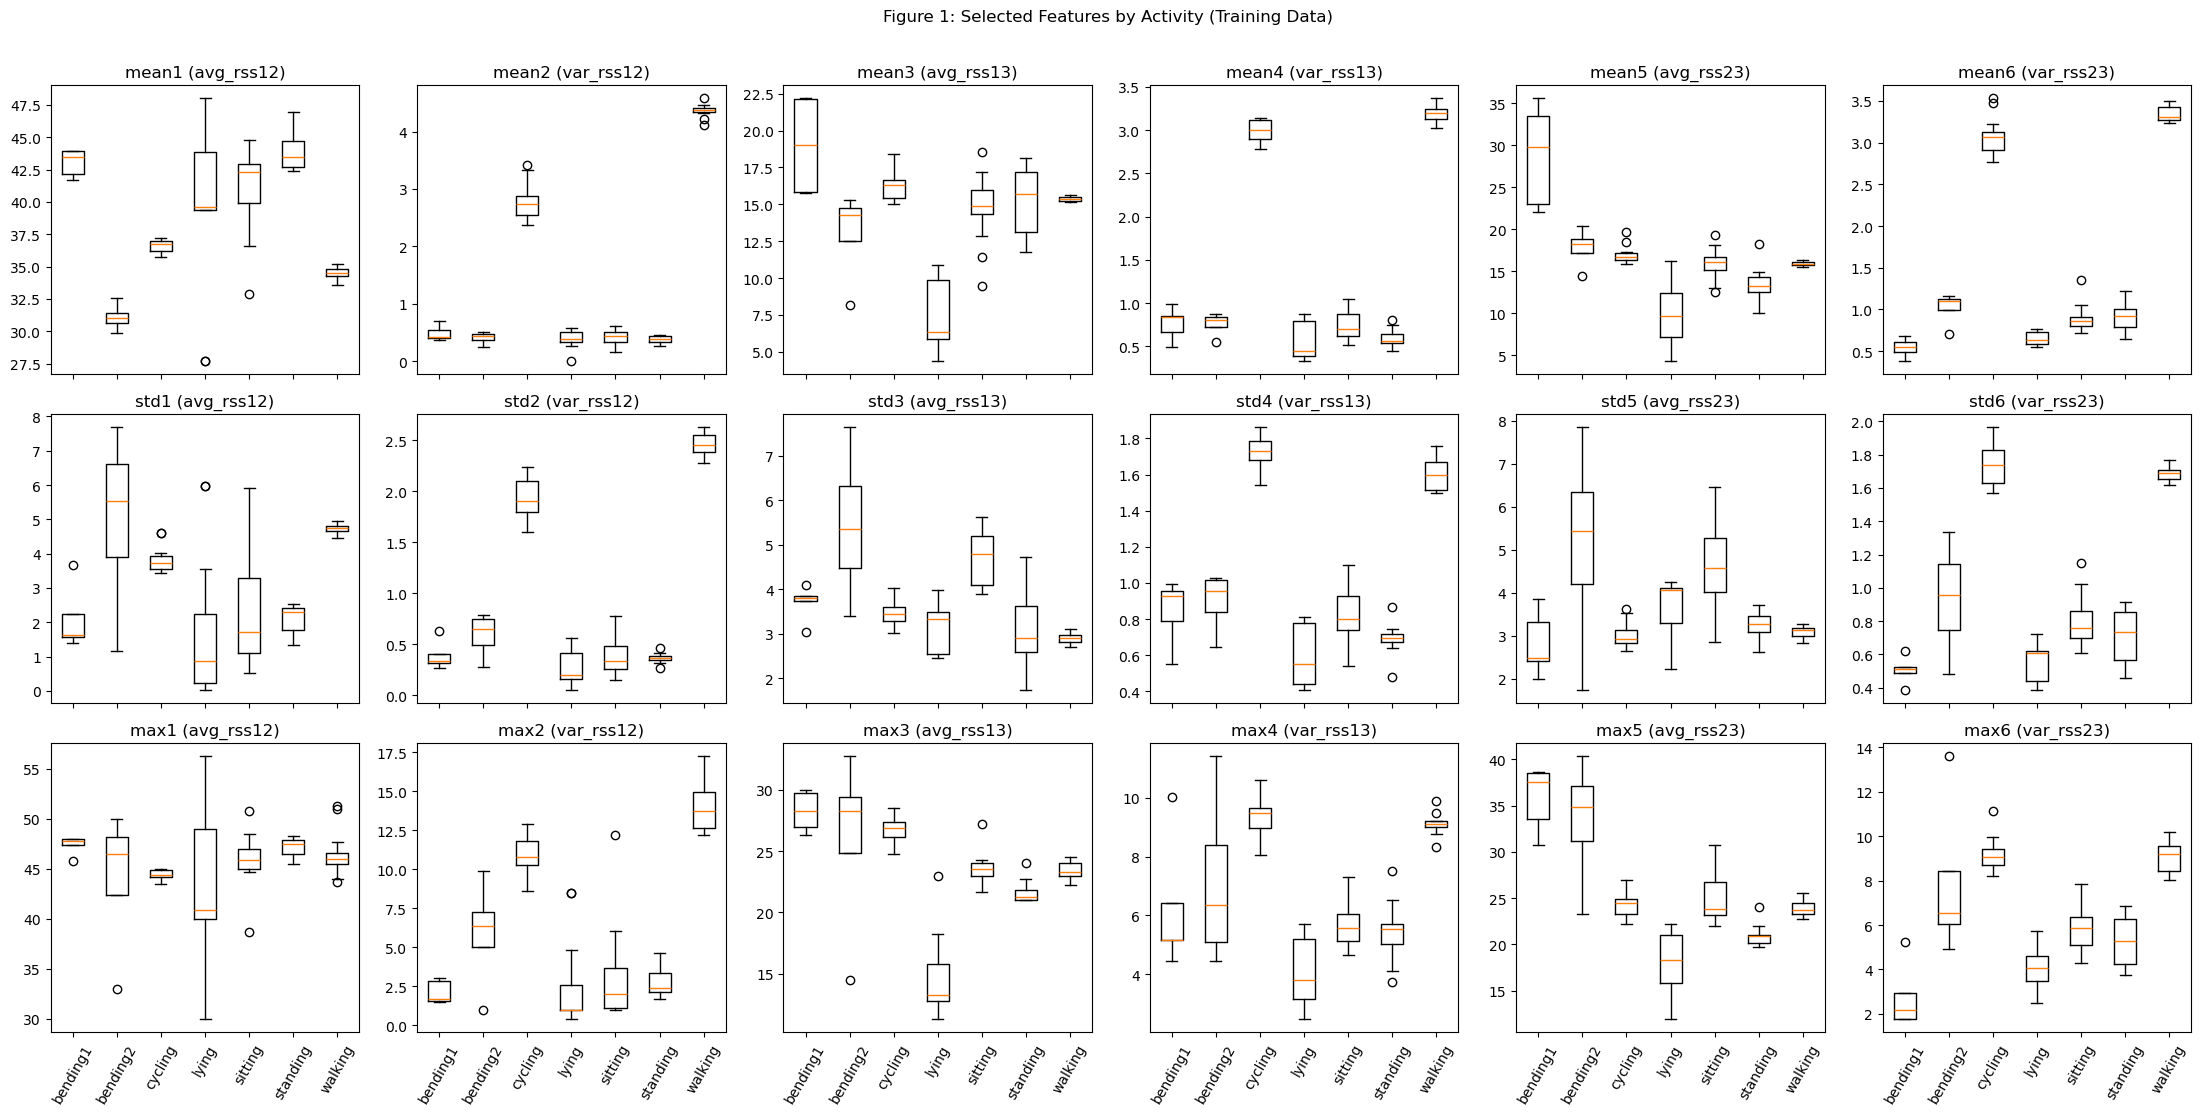

In [9]:
# Boxplots of the three selected feature types by activity (training data)
selected_types = ["mean", "std", "max"]
activities = list(train_activity.unique())

fig, axes = plt.subplots(len(selected_types), 6, figsize=(22, 11), sharex=True)
for r, feature_type in enumerate(selected_types):
    for c, series in enumerate(series_names):
        feature = f"{feature_type}{c + 1}"
        ax = axes[r, c]
        ax.boxplot([train_features.loc[train_activity == a, feature] for a in activities])
        ax.set_xticks(range(1, len(activities) + 1), labels=activities, rotation=60)
        ax.set_title(f"{feature} ({series})")
fig.suptitle("Figure 1: Selected Features by Activity (Training Data)", y=1.01)
plt.tight_layout()
plt.show()

I'd select mean, standard deviation, and maximum

The choice is based on the training data only, using two questions: how well does a feature type separate the seven activities (used one-way ANOVA F-statistic for this), and how much new information does it add to the features already chosen (correlation between feature types).

# Question 2

(a) The cubic regression would have the lower training RSS. The linear model is a special case of the cubic model (with the coefficients of X² and X³ set to 0), so least squares on the cubic model can always fit the training data at least as well. The extra terms fit some of the noise, so the cubic training RSS will be lower even though the true relationship is linear

(b) The linear regression would be expected to have the lower test RSS; since the true relationship is linear, the linear model has no bias, and the extra terms in the cubic model only add variance by fitting noise in the training data

(c) The cubic regression would have the lower training RSS. The reasoning is the same as in part a; the cubic model is more flexible and contains the linear model, so its training RSS can never be higher, no matter what the true relationship is.

(d) There is not enough information to tell. It depends on how far the true relationship is from linear. If it is close to linear, the linear model could have the lower test RSS, because its small bias is outweighed by the extra variance of the cubic model. If it is far from linear, the cubic model would have the lower test RSS, because the reduction in bias is larger than the increase in variance.

## References
- AReM data set (UCI Machine Learning Repository): https://archive.ics.uci.edu/dataset/366/activity+recognition+system+based+on+multisensor+data+fusion+arem
- James, Witten, Hastie, Tibshirani, *An Introduction to Statistical Learning* (ISLR), Chapter 3 (Question 2) and Section 5.2 (the bootstrap)
- `numpy.percentile` (percentile bootstrap interval): https://numpy.org/doc/stable/reference/generated/numpy.percentile.html
- `scipy.stats.f_oneway` (one-way ANOVA F-statistic): https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.f_oneway.html
- `pandas.read_csv` (regular expression separators and comment lines): https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html